In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/weight-height.csv')
df.sample(5)

,Gender,Height,Weight
2075,Male,69.643408,195.033701
5245,Female,65.296868,150.253650
6318,Female,59.436151,111.864140
7120,Female,65.056411,151.113500
920,Male,65.975207,171.076831


In [4]:
df['Height'].describe()

count    10000.000000
mean        66.367560
std          3.847528
min         54.263133
25%         63.505620
50%         66.318070
75%         69.174262
max         78.998742
Name: Height, dtype: float64

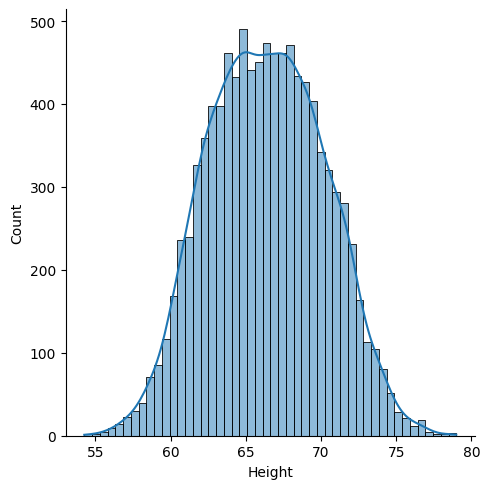

In [6]:
sns.displot(df['Height'], kde=True)

<Axes: ylabel='Height'>

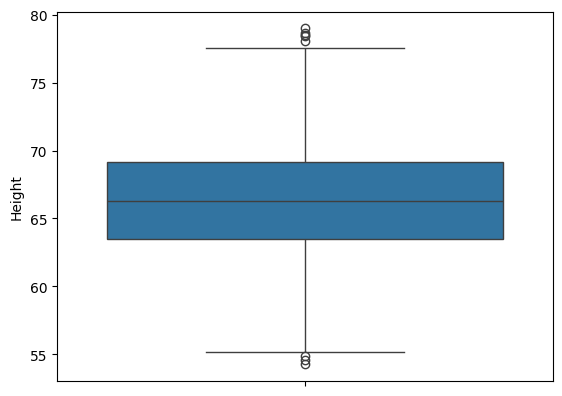

In [7]:
sns.boxplot(df['Height'])

In [8]:
upper_limit = df['Height'].quantile(0.99)
upper_limit

np.float64(74.7857900583366)

In [9]:
lower_limit = df['Height'].quantile(0.01)
lower_limit

np.float64(58.13441158671655)

In [10]:
df[(df['Height'] < lower_limit) | (df['Height'] > upper_limit)]

,Gender,Height,Weight
23,Male,75.205974,228.761781
190,Male,76.709835,235.035419
197,Male,75.944460,231.924749
202,Male,75.140821,224.124271
215,Male,74.795375,232.635403
...,...,...,...
9761,Female,56.975279,90.341784
9825,Female,55.979198,85.417534
9895,Female,57.740192,93.652957
9904,Female,57.028857,101.202551


In [13]:
new_df = df[(df['Height'] >= lower_limit) & (df['Height'] <= upper_limit)]
new_df

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801
...,...,...,...
9995,Female,66.172652,136.777454
9996,Female,67.067155,170.867906
9997,Female,63.867992,128.475319
9998,Female,69.034243,163.852461


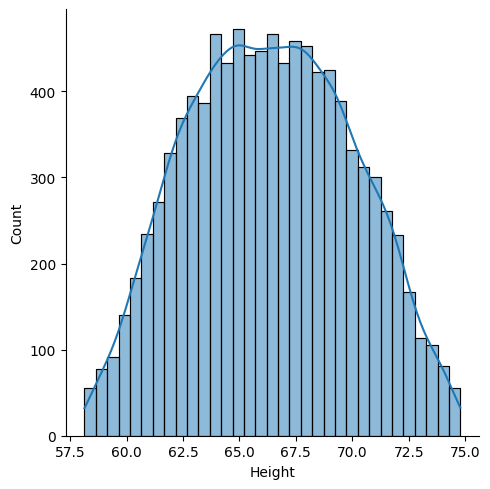

In [15]:
sns.displot(new_df['Height'],kde=True)

<Axes: ylabel='Height'>

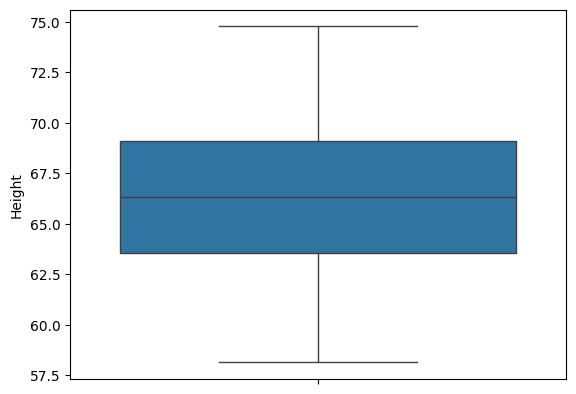

In [16]:
sns.boxplot(new_df['Height'])

# Capping

In [17]:
df['Height'] = np.where(
    df['Height'] >= upper_limit,
    upper_limit,
    np.where(
        df['Height'] <= lower_limit,
        lower_limit,
        df['Height']
    )
)

In [18]:
df['Height'].describe()

count    10000.000000
mean        66.366281
std          3.795717
min         58.134412
25%         63.505620
50%         66.318070
75%         69.174262
max         74.785790
Name: Height, dtype: float64

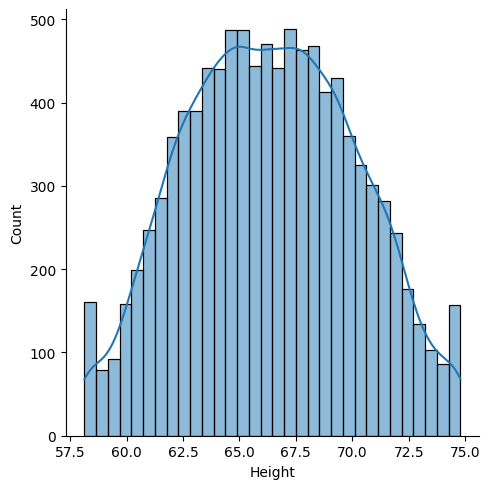

In [19]:
sns.displot(df['Height'], kde=True)

<Axes: ylabel='Height'>

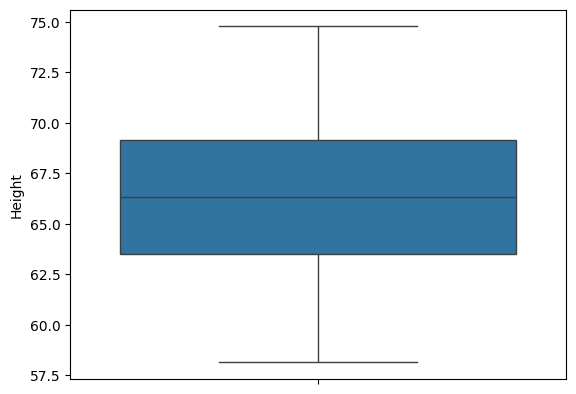

In [20]:
sns.boxplot(df['Height'])